# Why complex systems surprise us in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/01-surprise.ipynb)

Sensible people make sensible decisions, and the result is often the opposite of what they wanted. This notebook runs three small LoopBricks models in which a reasonable policy backfires: overtime that lowers output, a faster reaction that makes swings bigger, and a good change that gets judged a failure because its effect arrives late. In each case you will find the feedback or the delay that causes the surprise.

The ideas are taught in the app module [Why complex systems surprise us](https://waelrash1.github.io/loopbricks/#/learn/surprise).

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Working harder, getting less

A team is behind, so the manager asks for overtime. Output goes up straight away, which looks like success. But long hours build up **fatigue**, slowly, and tired people get less done in each hour. The **Productivity & Fatigue** molecule (`prodFatigue`) holds both effects. `Overtime` is hours worked relative to normal, so 1.4 means 40% more hours; `Output` is in tasks a week.

overtime  week 0  week 5  week 20  week 60  total over 60 weeks
       1     100     100      100      100        6000
     1.2     120     103       96       96        5856
     1.4     140     100       84       84        5264


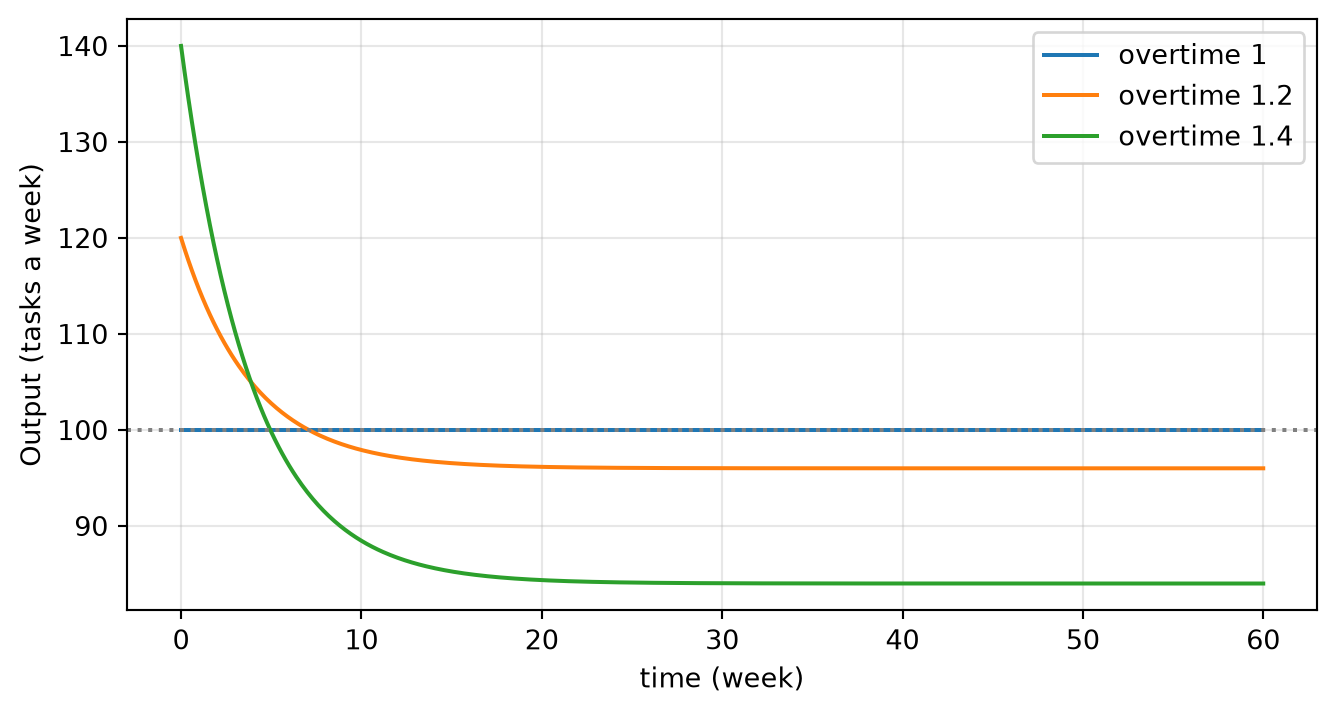

In [2]:
pf = lb.molecule("prodFatigue")
fig, ax = plt.subplots(figsize=(8, 4))
for ot in (1, 1.2, 1.4):
    pf.run(overtime=ot)["Output"].plot(ax=ax, label=f"overtime {ot}")
ax.axhline(100, ls=":", c="grey"); ax.set_ylabel("Output (tasks a week)"); ax.legend(); ax.grid(alpha=0.3)

print("overtime  week 0  week 5  week 20  week 60  total over 60 weeks")
for ot in (1, 1.2, 1.4):
    out = pf.run(overtime=ot)["Output"]
    total = out.iloc[:-1].sum() * pf.dt          # add up output week by week
    print(f"{ot:>8}  {out.loc[0.0]:6.0f}  {out.loc[5.0]:6.0f}  {out.loc[20.0]:7.0f}  {out.loc[60.0]:7.0f}  {total:10.0f}")

With 40% more hours, output jumps to 140 in the first week. By week 5 it has sunk back to the normal 100, and it settles at 84, which is 16% *below* what the team produced on normal hours. Over the 60 weeks the crunch delivers about 5,260 tasks against 6,000 without it. The gain comes first and the loss comes later, and that is why the policy looks good to the person who chose it.

The reason is a **balancing loop**: more hours, more fatigue, less output per hour. It works against the policy, slowly enough that nobody connects the two.

**Try it.** Is there any level of overtime that leaves the team producing more once fatigue has settled? Sweep the `overtime` parameter from 1 to 1.6 and look at the output in week 60.

<details><summary>Show a worked answer</summary>

No. In this model fatigue settles at the overtime level, and the effect of fatigue is then 2 minus the overtime, so long-run output is 100 × overtime × (2 − overtime). That is largest at overtime 1. The sweep below gives 100, 99, 96, 91, 84, 75 and 64 for overtime 1.0 to 1.6: every extra hour costs output in the end, and the cost grows faster than the hours.
</details>

In [3]:
for ot in (1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6):
    print(f"overtime {ot}: output in week 60 = {pf.run(overtime=ot)['Output'].iloc[-1]:.0f}")

overtime 1.0: output in week 60 = 100
overtime 1.1: output in week 60 = 99
overtime 1.2: output in week 60 = 96
overtime 1.3: output in week 60 = 91
overtime 1.4: output in week 60 = 84
overtime 1.5: output in week 60 = 75
overtime 1.6: output in week 60 = 64


## 2. Reacting faster to a shortage

A shop has 60 units in stock and wants 100. Goods take about six weeks to arrive from the supplier. The **Low-Visibility Pipeline Correction** molecule (`lowVisPipeline`) orders to close the gap. Its `Time to correct inventory` says how fast the buyer tries to close it, and `Awareness of pipeline` says whether the buyer counts the orders already on their way (1) or forgets them (0).

The obvious advice to a buyer who is short is: react faster. Here is what that does to a buyer who forgets the pipeline.

weeks to correct   peak (forgets pipeline)   peak (counts pipeline)
               8                     106.3                     98.5
               4                     117.2                    100.0
               2                     132.1                    104.8
               1                     162.5                    123.7


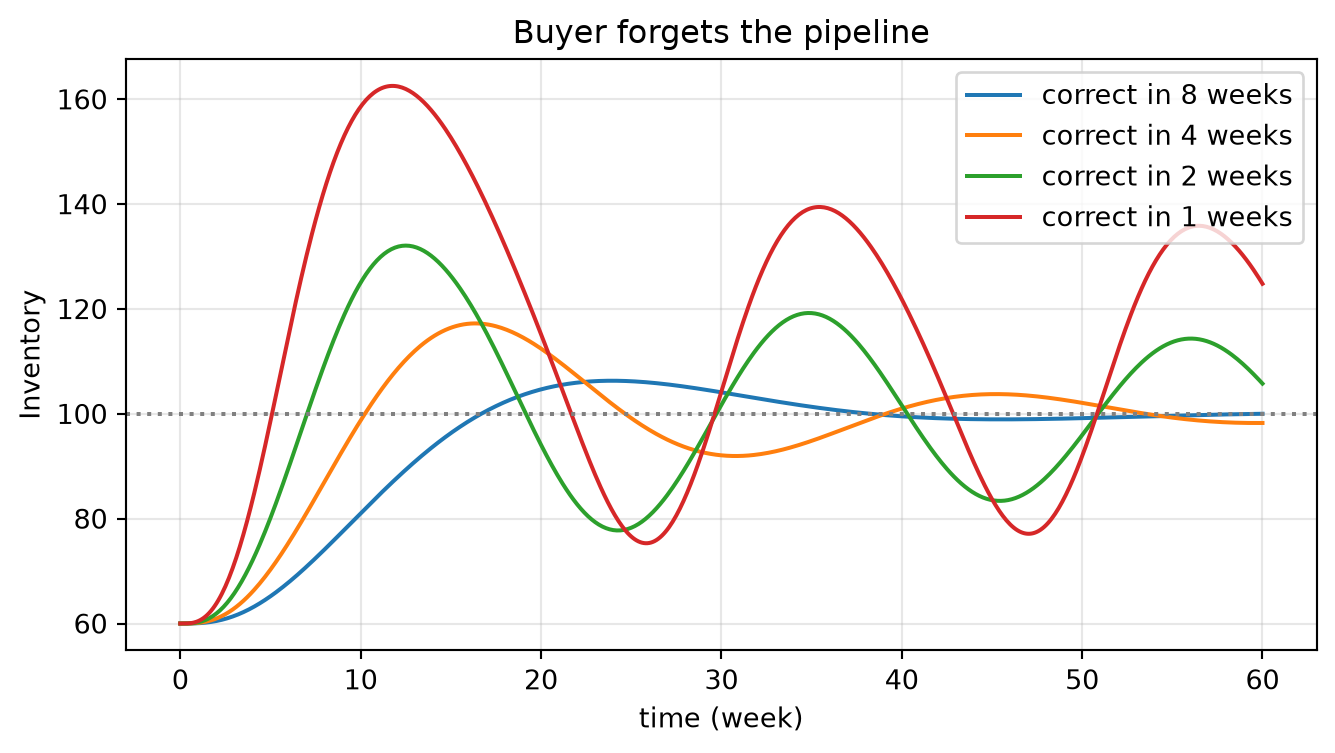

In [4]:
lv = lb.molecule("lowVisPipeline")
fig, ax = plt.subplots(figsize=(8, 4))
for tc in (8, 4, 2, 1):
    lv.run(awareness_of_pipeline=0, time_to_correct_inventory=tc)["Inventory"].plot(ax=ax, label=f"correct in {tc} weeks")
ax.axhline(100, ls=":", c="grey"); ax.set_ylabel("Inventory"); ax.set_title("Buyer forgets the pipeline")
ax.legend(); ax.grid(alpha=0.3)

print("weeks to correct   peak (forgets pipeline)   peak (counts pipeline)")
for tc in (8, 4, 2, 1):
    blind = lv.run(awareness_of_pipeline=0, time_to_correct_inventory=tc)["Inventory"]
    aware = lv.run(awareness_of_pipeline=1, time_to_correct_inventory=tc)["Inventory"]
    print(f"{tc:>16}   {blind.max():23.1f}   {aware.max():22.1f}")

The faster the buyer reacts, the worse it gets: the peak climbs from 106 to 117, 132 and 162 as the correction time falls from 8 weeks to 1. While the first orders are still on the road, inventory is still low, so the buyer orders again, and again. When it all arrives, the shop is overstocked. With a one-week correction the stock is still swinging between about 92 and 136 in the last ten weeks of the run.

A buyer who counts the pipeline does far better at every speed. The trouble was never the speed, it was the **delay** between ordering and receiving that the buyer did not see.

**Try it.** For a buyer who counts the pipeline, what is the fastest correction time (of 8, 4, 2 and 1 weeks) that keeps the peak within 5% of the target?

<details><summary>Show a worked answer</summary>

Two weeks. The table shows peaks of 98.5, 100.0 and 104.8 for 8, 4 and 2 weeks, all within 5% of 100, and 123.7 for one week. Even a buyer who sees everything can overreact if the reaction is much faster than the supply delay of six weeks.
</details>

## 3. Judging a change too early

Suppose a real improvement happens overnight: a measure jumps from 30 to 70. Nobody sees it overnight. Reports are averaged, people need time to notice, and opinions change slowly. The **Smooth** molecule (`smooth`) shows how a perception catches up with a real change. A **first-order** smooth reacts at once but slowly; a **third-order** smooth (three smoothing stages in a row) hardly moves at first and then catches up. Both use a smoothing time of 6 weeks here.

week  first order sees  third order sees  (share of the change of 40)
   2               27%                7%
   4               48%               31%
   6               63%               57%
  12               86%               94%
  18               95%               99%


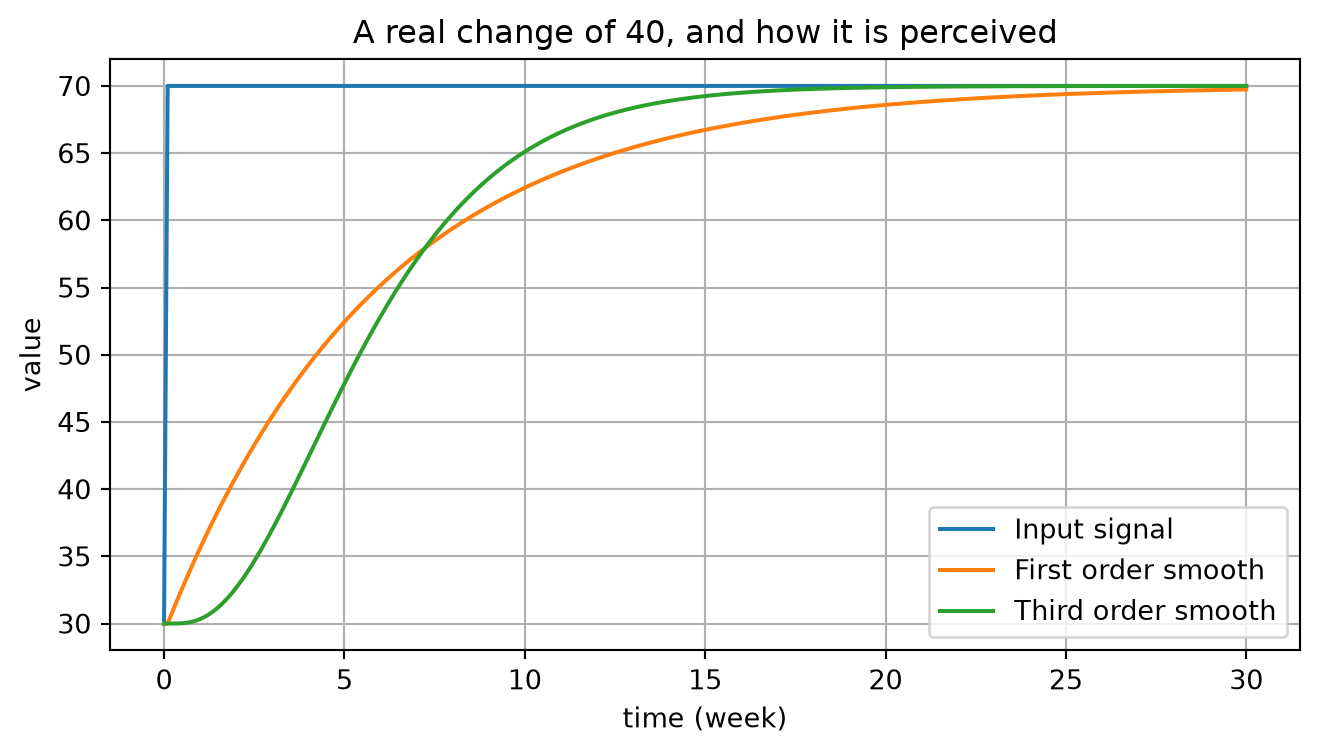

In [5]:
sm = lb.molecule("smooth")
df = sm.run()
df[["Input signal", "First order smooth", "Third order smooth"]].loc[:30].plot(figsize=(8, 4), grid=True)
plt.ylabel("value"); plt.title("A real change of 40, and how it is perceived")

print("week  first order sees  third order sees  (share of the change of 40)")
for wk in (2.0, 4.0, 6.0, 12.0, 18.0):
    f, t = df.loc[wk, "First order smooth"], df.loc[wk, "Third order smooth"]
    print(f"{wk:4.0f}  {100 * (f - 30) / 40:15.0f}%  {100 * (t - 30) / 40:15.0f}%")

Two weeks after the change, the first-order perception has registered about a quarter of it and the third-order one only 7%. If people judge the change after two weeks, the evidence says it barely worked. By week 12 both show most of it. Many good policies are dropped, and many bad ones kept, because results are judged before the delay has passed.

**Try it.** Run the *Slow (τ=15)* preset, where the measure jumps to 80 and the smoothing time is 15 weeks. When does each perception first show at least half of the change (a value of 55)?

<details><summary>Show a worked answer</summary>

The first-order perception reaches 55 in week 10.5 and the third-order one in week 13.5 (the cell below finds them). Both are close to the smoothing time of 15 weeks, so a quick rule of thumb holds: before you judge a change, wait roughly as long as the delay in seeing it.
</details>

In [6]:
slow = sm.run(preset="Slow (τ=15)")
for col in ("First order smooth", "Third order smooth"):
    print(col, "reaches 55 in week", slow.index[slow[col] >= 55][0])

First order smooth reaches 55 in week 10.5
Third order smooth reaches 55 in week 13.5


## Where next

- Back in the app: the [Why complex systems surprise us](https://waelrash1.github.io/loopbricks/#/learn/surprise) module tells the story behind these runs. The [Feedback loops and causal diagrams](https://waelrash1.github.io/loopbricks/#/learn/loops) module explains the compensating feedback in section 1, and [Delays and perception](https://waelrash1.github.io/loopbricks/#/learn/delays) and [Oscillation](https://waelrash1.github.io/loopbricks/#/learn/oscillation) go deeper into sections 2 and 3.
- Next notebook: [Stocks, flows and accumulation](https://waelrash1.github.io/loopbricks/#/learn/stocks-flows), the building blocks every model here is made of.
- Every molecule takes its constants as keyword arguments: `pf.params` lists them and `pf.presets` the named scenarios.